# Carregamento e inspeção inicial do TrashNet

Inspeção inicial das divisões, atributos, rótulos, distribuição das classes e amostras visuais. Este notebook não treina nem avalia um modelo.

> **Armazenamento:** a página do Hugging Face informa tamanho total de cerca de 3,68 GB. A execução de `load_dataset` pode transferir arquivos para o cache do ambiente. Verifique o espaço disponível antes da execução.

In [10]:
%pip -q install datasets matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\lucas\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


## 1. Carregar o dataset local

O conjunto TrashNet foi extraído para a pasta `trashnet/`. O carregador `imagefolder` usa os nomes das subpastas como rótulos e cria uma divisão inicial chamada `train`. Essa divisão ainda será separada em treino, validação e teste.

In [11]:
from pathlib import Path
from datasets import load_dataset

caminhos_candidatos = [
    Path("trashnet/dataset-resized/dataset-resized"),
    Path("../trashnet/dataset-resized/dataset-resized"),
]
caminho_dataset = next((caminho for caminho in caminhos_candidatos if caminho.is_dir()), None)
if caminho_dataset is None:
    caminhos_verificados = ", ".join(str(caminho.resolve()) for caminho in caminhos_candidatos)
    raise FileNotFoundError(f"Pasta do TrashNet não encontrada. Caminhos verificados: {caminhos_verificados}")

ds = load_dataset("imagefolder", data_dir=str(caminho_dataset))
ds

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 2527
    })
})

## 2. Conferir divisões, campos e classes

A página do dataset apresenta uma divisão chamada `train`. Essa divisão não substitui conjuntos separados de treino, validação e teste; a separação será definida posteriormente.

In [12]:
print("Divisões disponíveis:", list(ds.keys()))
treino = ds["train"]
print("Quantidade de exemplos:", len(treino))
print("Campos:", treino.features)
print("Nomes das classes:", treino.features["label"].names)

Divisões disponíveis: ['train']
Quantidade de exemplos: 2527
Campos: {'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash'])}
Nomes das classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


## 3. Contar exemplos por classe

A contagem descreve o dataset carregado e não é uma métrica do modelo. Ela permite identificar diferenças no número de exemplos entre as classes.

In [13]:
from collections import Counter

contagens = Counter(treino["label"])
nomes = treino.features["label"].names
for indice, nome in enumerate(nomes):
    print(f"{nome:10} {contagens[indice]:5} imagens")

cardboard    403 imagens
glass        501 imagens
metal        410 imagens
paper        594 imagens
plastic      482 imagens
trash        137 imagens


## 4. Olhar exemplos

A inspeção visual permite verificar se as imagens são legíveis e se os rótulos parecem coerentes. As imagens do TrashNet foram fotografadas principalmente sobre fundo branco; os resultados serão comparados posteriormente com fotos reais da equipe.

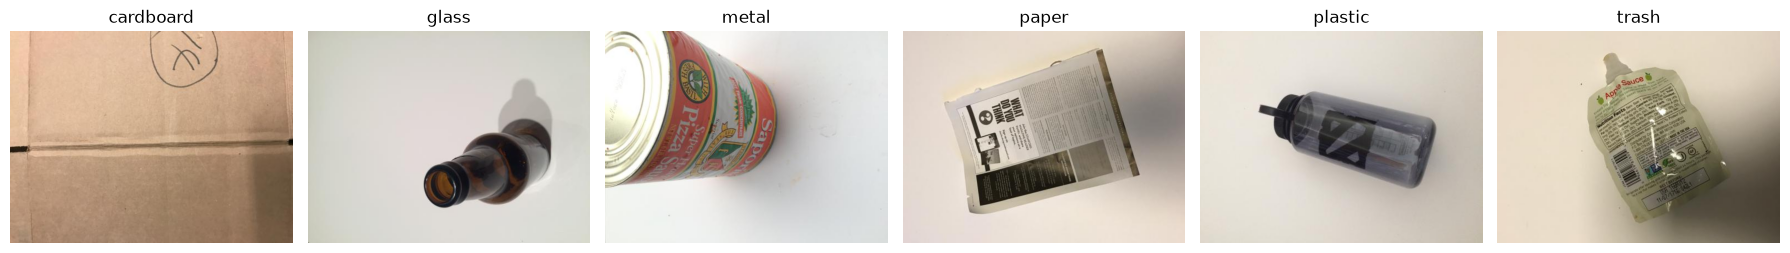

In [14]:
import matplotlib.pyplot as plt

nomes = treino.features["label"].names
fig, eixos = plt.subplots(1, len(nomes), figsize=(3 * len(nomes), 3))

for indice_classe, eixo in enumerate(eixos):
    indice_imagem = next(
        indice
        for indice, rotulo in enumerate(treino["label"])
        if rotulo == indice_classe
    )
    exemplo = treino[indice_imagem]
    eixo.imshow(exemplo["image"].convert("RGB"))
    eixo.set_title(nomes[indice_classe])
    eixo.axis("off")

plt.tight_layout()

## Saídas a registrar

1. Divisões disponíveis.
2. Número total de exemplos carregados.
3. Nomes e contagens por classe.
4. Coerência visual entre imagens e rótulos.

A próxima etapa é criar uma divisão estratificada de treino, validação e teste. As fotos reais serão mantidas separadas para permitir uma avaliação independente do domínio de captura.

## 5. Preparar treino, validação e teste

A divisão é estratificada para manter aproximadamente a proporção de cada classe nos três conjuntos. A semente fixa torna o resultado reproduzível. A proporção planejada é 70% para treino, 15% para validação e 15% para teste.

In [15]:
from datasets import DatasetDict

dataset_completo = ds["train"]
separacao = dataset_completo.train_test_split(
    test_size=0.30,
    seed=42,
    stratify_by_column="label",
)
separacao_temporaria = separacao["test"].train_test_split(
    test_size=0.50,
    seed=42,
    stratify_by_column="label",
)

divisoes = DatasetDict({
    "train": separacao["train"],
    "validation": separacao_temporaria["train"],
    "test": separacao_temporaria["test"],
})

nomes = dataset_completo.features["label"].names
for nome_divisao, conjunto in divisoes.items():
    contagens = Counter(conjunto["label"])
    print(f"{nome_divisao}: {len(conjunto)} imagens")
    for indice_classe, nome_classe in enumerate(nomes):
        print(f"  {nome_classe:10} {contagens[indice_classe]:4} imagens")


train: 1768 imagens
  cardboard   282 imagens
  glass       350 imagens
  metal       287 imagens
  paper       416 imagens
  plastic     337 imagens
  trash        96 imagens
validation: 379 imagens
  cardboard    61 imagens
  glass        75 imagens
  metal        61 imagens
  paper        89 imagens
  plastic      72 imagens
  trash        21 imagens
test: 380 imagens
  cardboard    60 imagens
  glass        76 imagens
  metal        62 imagens
  paper        89 imagens
  plastic      73 imagens
  trash        20 imagens
